# Sri Lankan Household Electricity Consumption Prediction Using Ensemble Learning
224227F - Dewasurendra W.D.S.H.

## Project Overview

This project explores different ensemble learning techniques to predict household electricity consumption in Sri Lanka.

The project focuses on comparing Bagging, Boosting, and Stacking algorithms using historical household electricity consumption data from the RECON-SL dataset.

## Objectives

1. Explore and preprocess the Sri Lankan household electricity consumption dataset.
2. Implement different ensemble learning techniques for electricity consumption prediction.
3. Compare Decision Tree, Bagging, Random Forest, Gradient Boosting, and XGBoost models.
4. Experiment with Stacking to improve prediction performance.
5. Evaluate and compare model performance using MAE, MSE, RMSE, and R² score.
6. Identify the most influential features affecting household electricity consumption.
7. Develop an interactive dashboard to visualize model performance and predict future household electricity consumption.

**AI-use declaration:** The code structure, the dashboard front end and the draft explanations in this notebook were generated with the help of an AI tool (ChatGPT). I reviewed, ran and adapted them, and the dataset choice the experiment settings and the final interpretation of the results are mine.

## Imports

In [25]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import TimeSeriesSplit
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    GradientBoostingClassifier,
    StackingClassifier
)

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

# XGBoost
from xgboost import XGBClassifier

# Other libraries
import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("All libraries imported successfully!")

All libraries imported successfully!


## Load the data set

In [26]:
df = pd.read_csv("../data/raw/monthly_consumption.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Inspect the data set

In [3]:
df.head(10)

,household_ID,month,consumption
0,ID0001,2022-10-31,116
1,ID0001,2022-11-30,120
2,ID0001,2022-12-31,129
3,ID0001,2023-01-31,102
4,ID0001,2023-02-28,115
5,ID0001,2023-03-31,97
6,ID0001,2023-04-30,94
7,ID0001,2023-05-31,98
8,ID0001,2023-06-30,87
9,ID0001,2023-07-31,109


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (101575, 3)

Column names:
['household_ID', 'month', 'consumption']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 101575 entries, 0 to 101574
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   household_ID  101575 non-null  str  
 1   month         101575 non-null  str  
 2   consumption   100985 non-null  str  
dtypes: str(3)
memory usage: 4.1 MB


In [5]:
df.isnull().sum()

household_ID      0
month             0
consumption     590
dtype: int64

In [6]:
df.describe()

,household_ID,month,consumption
count,101575,101575,100985
unique,4063,25,1134
top,ID0001,2022-10-31,0
freq,25,4063,2332


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101575 entries, 0 to 101574
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   household_ID  101575 non-null  str  
 1   month         101575 non-null  str  
 2   consumption   100985 non-null  str  
dtypes: str(3)
memory usage: 4.1 MB


In [8]:
# Check sample values
print("Sample records:")
display(df.head(10))

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check unique month values
print("\nSample month values:")
print(df["month"].unique()[:15])

# Check consumption values
print("\nSample consumption values:")
print(df["consumption"].unique()[:20])

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

Sample records:


,household_ID,month,consumption
0,ID0001,2022-10-31,116
1,ID0001,2022-11-30,120
2,ID0001,2022-12-31,129
3,ID0001,2023-01-31,102
4,ID0001,2023-02-28,115
5,ID0001,2023-03-31,97
6,ID0001,2023-04-30,94
7,ID0001,2023-05-31,98
8,ID0001,2023-06-30,87
9,ID0001,2023-07-31,109



Missing values:
household_ID      0
month             0
consumption     590
dtype: int64

Sample month values:
<ArrowStringArray>
['2022-10-31', '2022-11-30', '2022-12-31', '2023-01-31', '2023-02-28',
 '2023-03-31', '2023-04-30', '2023-05-31', '2023-06-30', '2023-07-31',
 '2023-08-31', '2023-09-30', '2023-10-31', '2023-11-30', '2023-12-31']
Length: 15, dtype: str

Sample consumption values:
<ArrowStringArray>
['116', '120', '129', '102', '115',  '97',  '94',  '98',  '87', '109', '100',
 '101',  '93',  '85',  '82',  '67',  '92',   '0', '106',  '63']
Length: 20, dtype: str

Duplicate records: 0


## Preprocess Data

In [27]:
# Convert month to datetime
df["month"] = pd.to_datetime(df["month"], errors="coerce")

# Convert consumption to numeric
df["consumption"] = pd.to_numeric(
    df["consumption"], errors="coerce"
)

# Check updated data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101575 entries, 0 to 101574
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   household_ID  101575 non-null  str           
 1   month         101575 non-null  datetime64[us]
 2   consumption   100928 non-null  float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 2.9 MB


In [10]:
# Check duplicate household-month combinations
duplicate_household_months = df.duplicated(
    subset=["household_ID", "month"]
).sum()

print("Duplicate household-month records:",
      duplicate_household_months)

Duplicate household-month records: 0


In [11]:
# Number of households
print("Number of unique households:",
      df["household_ID"].nunique())

# Number of unique months
print("Number of unique months:",
      df["month"].nunique())

# Records available for each month
monthly_records = df.groupby("month").size()

display(monthly_records)

Number of unique households: 4063
Number of unique months: 25


month
2022-10-31    4063
2022-11-30    4063
2022-12-31    4063
2023-01-31    4063
2023-02-28    4063
2023-03-31    4063
2023-04-30    4063
2023-05-31    4063
2023-06-30    4063
2023-07-31    4063
2023-08-31    4063
2023-09-30    4063
2023-10-31    4063
2023-11-30    4063
2023-12-31    4063
2024-01-31    4063
2024-02-29    4063
2024-03-31    4063
2024-04-30    4063
2024-05-31    4063
2024-06-30    4063
2024-07-31    4063
2024-08-31    4063
2024-09-30    4063
2024-10-31    4063
dtype: int64

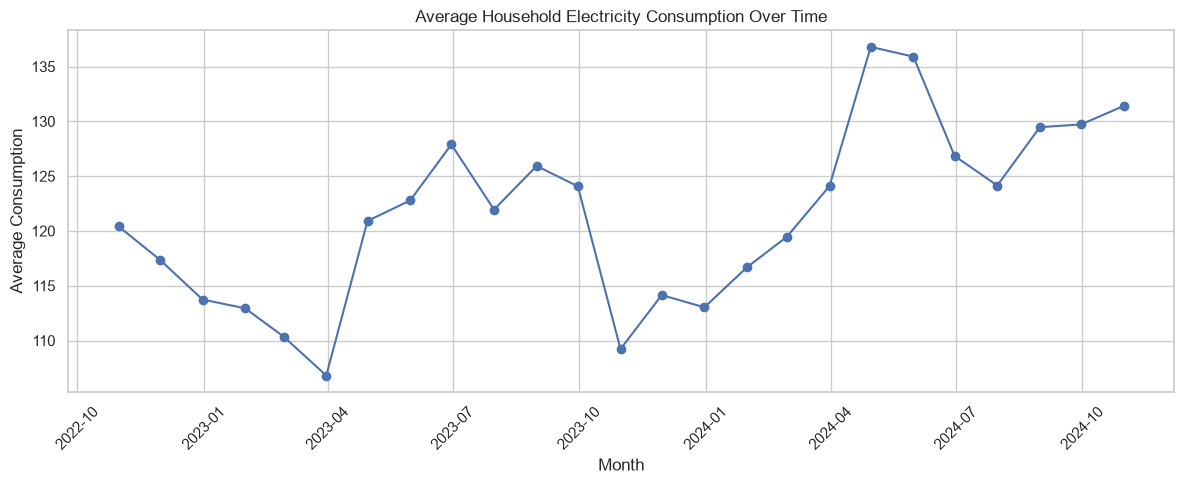

In [12]:
monthly_consumption = df.groupby("month")["consumption"].mean()

plt.figure(figsize=(12, 5))
plt.plot(monthly_consumption.index,
         monthly_consumption.values,
         marker="o")

plt.title("Average Household Electricity Consumption Over Time")
plt.xlabel("Month")
plt.ylabel("Average Consumption")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
# Check missing consumption values by month
missing_by_month = (
    df.groupby("month")["consumption"]
    .apply(lambda x: x.isnull().sum())
)

print("Missing consumption values by month:")
display(missing_by_month)

Missing consumption values by month:


month
2022-10-31    43
2022-11-30    31
2022-12-31    24
2023-01-31    15
2023-02-28     5
2023-03-31    16
2023-04-30    12
2023-05-31    12
2023-06-30    14
2023-07-31    15
2023-08-31    26
2023-09-30    26
2023-10-31    29
2023-11-30    26
2023-12-31    35
2024-01-31    29
2024-02-29    28
2024-03-31    27
2024-04-30    32
2024-05-31    30
2024-06-30    29
2024-07-31    33
2024-08-31    34
2024-09-30    38
2024-10-31    38
Name: consumption, dtype: int64

In [14]:
# Check households with missing consumption
missing_households = df[
    df["consumption"].isnull()
]["household_ID"].nunique()

print("Households with missing consumption:",
      missing_households)

Households with missing consumption: 173


In [15]:
# Statistical summary
print("Consumption statistics:")
display(df["consumption"].describe())

# Number of zero consumption records
print("Zero consumption records:",
      (df["consumption"] == 0).sum())

Consumption statistics:


count    100928.000000
mean        121.434171
std         118.339870
min           0.000000
25%          60.000000
50%          96.000000
75%         148.000000
max        3025.000000
Name: consumption, dtype: float64

Zero consumption records: 2332


In [16]:
# Reload original dataset without modifying the current df
df_raw = pd.read_csv("../data/raw/monthly_consumption.csv")

# Identify non-empty values that cannot be converted to numbers
original_consumption = df_raw["consumption"]

numeric_values = pd.to_numeric(
    original_consumption, errors="coerce"
)

invalid_values = df_raw[
    original_consumption.notna() & numeric_values.isna()
]

print("Number of invalid values:", len(invalid_values))

display(invalid_values.head(20))

Number of invalid values: 57


,household_ID,month,consumption
9850,ID0395,2022-10-31,"1,644"
9851,ID0395,2022-11-30,"1,701"
9852,ID0395,2022-12-31,"1,346"
9853,ID0395,2023-01-31,"1,399"
9854,ID0395,2023-02-28,"1,297"
9855,ID0395,2023-03-31,"1,197"
9856,ID0395,2023-04-30,"1,159"
9857,ID0395,2023-05-31,"1,332"
9858,ID0395,2023-06-30,"1,652"
9859,ID0395,2023-07-31,"1,498"


In [17]:
# Check higher consumption percentiles
print("Consumption percentiles:")

display(
    df["consumption"].quantile(
        [0.90, 0.95, 0.99, 0.995, 1.00]
    )
)

Consumption percentiles:


0.900     224.0
0.950     304.0
0.990     568.0
0.995     731.0
1.000    3025.0
Name: consumption, dtype: float64

In [ ]:
# Reload the original dataset
df = pd.read_csv("../data/raw/monthly_consumption.csv")

# Convert month to datetime
df["month"] = pd.to_datetime(df["month"])

# Remove thousands separators and convert consumption to numeric
df["consumption"] = pd.to_numeric(
    df["consumption"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

# Check updated information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101575 entries, 0 to 101574
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   household_ID  101575 non-null  str           
 1   month         101575 non-null  datetime64[us]
 2   consumption   100985 non-null  Int64         
dtypes: Int64(1), datetime64[us](1), str(1)
memory usage: 3.0 MB


In [ ]:
print("Missing consumption values:")
print(df["consumption"].isnull().sum())

print("\nConsumption statistics:")
display(df["consumption"].describe())

print("\nZero consumption records:")
print((df["consumption"] == 0).sum())

print("\nRemaining invalid values:")
print(
    df["consumption"].isna().sum()
)

Missing consumption values:
590

Consumption statistics:


count      100985.0
mean      122.14412
std      122.217922
min             0.0
25%            60.0
50%            96.0
75%           148.0
max          3025.0
Name: consumption, dtype: Float64


Zero consumption records:
2332

Remaining invalid values:
590


Missing values by month:


month
2022-10-31    43
2022-11-30    31
2022-12-31    24
2023-01-31    15
2023-02-28     5
2023-03-31    16
2023-04-30    12
2023-05-31    12
2023-06-30    14
2023-07-31    15
2023-08-31    26
2023-09-30    26
2023-10-31    29
2023-11-30    26
2023-12-31    35
2024-01-31    29
2024-02-29    28
2024-03-31    27
2024-04-30    32
2024-05-31    30
2024-06-30    29
2024-07-31    33
2024-08-31    34
2024-09-30    38
2024-10-31    38
Name: consumption, dtype: int64

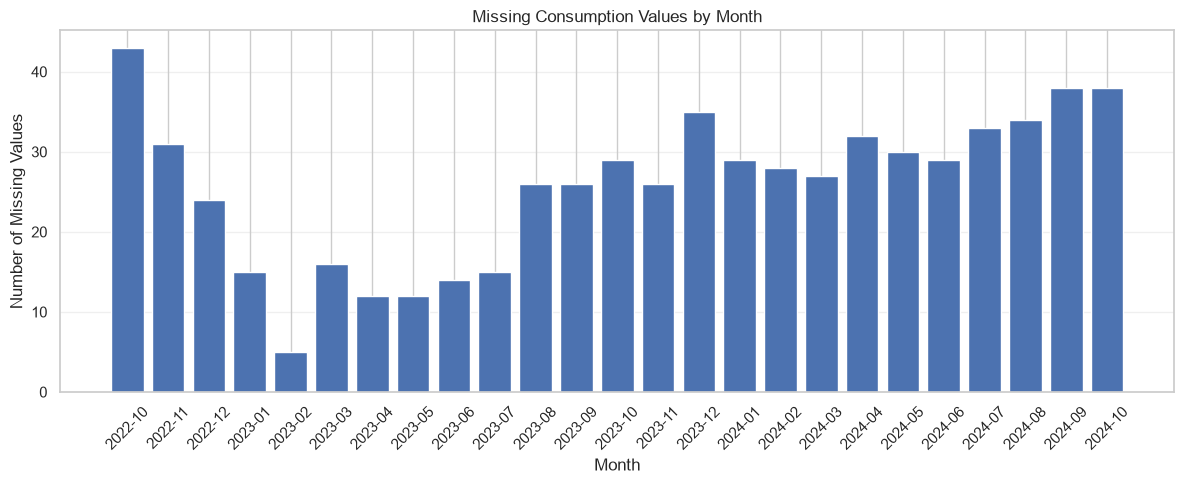

In [38]:
missing_by_month = (
    df.groupby("month")["consumption"]
    .apply(lambda x: x.isnull().sum())
)

print("Missing values by month:")
display(missing_by_month)

plt.figure(figsize=(12, 5))

plt.bar(
    missing_by_month.index.strftime("%Y-%m"),
    missing_by_month.values
)

plt.title("Missing Consumption Values by Month")
plt.xlabel("Month")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
missing_by_household = (
    df.groupby("household_ID")["consumption"]
    .apply(lambda x: x.isnull().sum())
)

print(
    "Households with missing values:",
    (missing_by_household > 0).sum()
)

print("\nMissing values per household:")
display(
    missing_by_household[missing_by_household > 0]
    .describe()
)

print("\nTop 10 households with missing values:")
display(
    missing_by_household[missing_by_household > 0]
    .sort_values(ascending=False)
    .head(10)
)

Households with missing values: 165

Missing values per household:


count    165.000000
mean       3.575758
std        4.045702
min        1.000000
25%        1.000000
50%        2.000000
75%        4.000000
max       20.000000
Name: consumption, dtype: float64


Top 10 households with missing values:


household_ID
ID2386    20
ID0334    18
ID0047    17
ID2090    17
ID0228    16
ID2238    15
ID2301    15
ID3824    15
ID3216    13
ID1695    13
Name: consumption, dtype: int64

In [ ]:
# Sort records by household and month
df = df.sort_values(
    by=["household_ID", "month"]
).reset_index(drop=True)

display(df.head(10))

,household_ID,month,consumption
0,ID0001,2022-10-31,116
1,ID0001,2022-11-30,120
2,ID0001,2022-12-31,129
3,ID0001,2023-01-31,102
4,ID0001,2023-02-28,115
5,ID0001,2023-03-31,97
6,ID0001,2023-04-30,94
7,ID0001,2023-05-31,98
8,ID0001,2023-06-30,87
9,ID0001,2023-07-31,109


In [30]:
# Create previous month consumption features
df["consumption_lag_1"] = (
    df.groupby("household_ID")["consumption"].shift(1)
)

df["consumption_lag_2"] = (
    df.groupby("household_ID")["consumption"].shift(2)
)

df["consumption_lag_3"] = (
    df.groupby("household_ID")["consumption"].shift(3)
)

display(df.head(10))

,household_ID,month,consumption,target,consumption_lag_1,consumption_lag_2,consumption_lag_3
0,ID0001,2022-10-31,116.0,120.0,NaN,NaN,NaN
1,ID0001,2022-11-30,120.0,129.0,116.0,NaN,NaN
2,ID0001,2022-12-31,129.0,102.0,120.0,116.0,NaN
3,ID0001,2023-01-31,102.0,115.0,129.0,120.0,116.0
4,ID0001,2023-02-28,115.0,97.0,102.0,129.0,120.0
5,ID0001,2023-03-31,97.0,94.0,115.0,102.0,129.0
6,ID0001,2023-04-30,94.0,98.0,97.0,115.0,102.0
7,ID0001,2023-05-31,98.0,87.0,94.0,97.0,115.0
8,ID0001,2023-06-30,87.0,109.0,98.0,94.0,97.0
9,ID0001,2023-07-31,109.0,100.0,87.0,98.0,94.0


In [31]:
# Target: next month's electricity consumption
df["target"] = (
    df.groupby("household_ID")["consumption"].shift(-1)
)

display(
    df[
        [
            "household_ID",
            "month",
            "consumption",
            "consumption_lag_1",
            "consumption_lag_2",
            "consumption_lag_3",
            "target"
        ]
    ].head(10)
)

,household_ID,month,consumption,consumption_lag_1,consumption_lag_2,consumption_lag_3,target
0,ID0001,2022-10-31,116.0,NaN,NaN,NaN,120.0
1,ID0001,2022-11-30,120.0,116.0,NaN,NaN,129.0
2,ID0001,2022-12-31,129.0,120.0,116.0,NaN,102.0
3,ID0001,2023-01-31,102.0,129.0,120.0,116.0,115.0
4,ID0001,2023-02-28,115.0,102.0,129.0,120.0,97.0
5,ID0001,2023-03-31,97.0,115.0,102.0,129.0,94.0
6,ID0001,2023-04-30,94.0,97.0,115.0,102.0,98.0
7,ID0001,2023-05-31,98.0,94.0,97.0,115.0,87.0
8,ID0001,2023-06-30,87.0,98.0,94.0,97.0,109.0
9,ID0001,2023-07-31,109.0,87.0,98.0,94.0,100.0


In [39]:
df["month_number"] = df["month"].dt.month
df["year"] = df["month"].dt.year

display(df.head())

,household_ID,month,consumption,target,consumption_lag_1,consumption_lag_2,consumption_lag_3,target_month,month_number,year
0,ID0001,2022-10-31,116.0,120.0,NaN,NaN,NaN,2022-11-30,10,2022
1,ID0001,2022-11-30,120.0,129.0,116.0,NaN,NaN,2022-12-31,11,2022
2,ID0001,2022-12-31,129.0,102.0,120.0,116.0,NaN,2023-01-31,12,2022
3,ID0001,2023-01-31,102.0,115.0,129.0,120.0,116.0,2023-02-28,1,2023
4,ID0001,2023-02-28,115.0,97.0,102.0,129.0,120.0,2023-03-31,2,2023


In [32]:
print("Dataset shape:", df.shape)

print("\nMissing values in engineered features:")
display(
    df[
        [
            "consumption_lag_1",
            "consumption_lag_2",
            "consumption_lag_3",
            "target"
        ]
    ].isnull().sum()
)

Dataset shape: (101575, 7)

Missing values in engineered features:


consumption_lag_1     4672
consumption_lag_2     8697
consumption_lag_3    12726
target                4667
dtype: int64

In [36]:
# Identify the month that each target value belongs to
df["target_month"] = (
    df.groupby("household_ID")["month"].shift(-1)
)

display(
    df[
        ["household_ID", "month", "target_month", "consumption", "target"]
    ].head(10)
)

,household_ID,month,target_month,consumption,target
0,ID0001,2022-10-31,2022-11-30,116.0,120.0
1,ID0001,2022-11-30,2022-12-31,120.0,129.0
2,ID0001,2022-12-31,2023-01-31,129.0,102.0
3,ID0001,2023-01-31,2023-02-28,102.0,115.0
4,ID0001,2023-02-28,2023-03-31,115.0,97.0
5,ID0001,2023-03-31,2023-04-30,97.0,94.0
6,ID0001,2023-04-30,2023-05-31,94.0,98.0
7,ID0001,2023-05-31,2023-06-30,98.0,87.0
8,ID0001,2023-06-30,2023-07-31,87.0,109.0
9,ID0001,2023-07-31,2023-08-31,109.0,100.0


In [40]:
feature_columns = [
    "consumption",
    "consumption_lag_1",
    "consumption_lag_2",
    "consumption_lag_3",
    "month_number",
    "year"
]

# Keep records with all required features and target
model_data = df.dropna(
    subset=feature_columns + ["target", "target_month"]
).copy()

print("Original dataset size:", len(df))
print("Dataset size after removing incomplete records:", len(model_data))
print("Removed records:", len(df) - len(model_data))

Original dataset size: 101575
Dataset size after removing incomplete records: 84300
Removed records: 17275


In [41]:
# Sort by target month
model_data = model_data.sort_values(
    by=["target_month", "household_ID"]
).reset_index(drop=True)

# Training: target months before June 2024
# Testing: target months from June 2024 onwards
cutoff_date = pd.Timestamp("2024-06-01")

train_data = model_data[
    model_data["target_month"] < cutoff_date
].copy()

test_data = model_data[
    model_data["target_month"] >= cutoff_date
].copy()

# Separate features and target
X_train = train_data[feature_columns]
y_train = train_data["target"]

X_test = test_data[feature_columns]
y_test = test_data["target"]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target months:")
print(train_data["target_month"].min(),
      "to",
      train_data["target_month"].max())

print("\nTesting target months:")
print(test_data["target_month"].min(),
      "to",
      test_data["target_month"].max())

Training samples: 64242
Testing samples: 20058

Training target months:
2023-02-28 00:00:00 to 2024-05-31 00:00:00

Testing target months:
2024-06-30 00:00:00 to 2024-10-31 00:00:00


In [ ]:
print("Training records per target month:")
display(train_data.groupby("target_month").size())

print("\nTesting records per target month:")
display(test_data.groupby("target_month").size())

Training records per target month:


target_month
2023-02-28    4004
2023-03-31    4008
2023-04-30    4015
2023-05-31    4022
2023-06-30    4031
2023-07-31    4031
2023-08-31    4027
2023-09-30    4030
2023-10-31    4023
2023-11-30    4023
2023-12-31    4012
2024-01-31    4012
2024-02-29    4013
2024-03-31    4016
2024-04-30    4014
2024-05-31    4020
dtype: int64


Testing records per target month:


target_month
2024-06-30    4021
2024-07-31    4018
2024-08-31    4017
2024-09-30    4015
2024-10-31    4013
dtype: int64

## Training Models

In [58]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create Decision Tree model
decision_tree = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

# Train the model
decision_tree.fit(X_train, y_train)

# Make predictions
dt_predictions = decision_tree.predict(X_test)

# Evaluate the model
dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_mse = mean_squared_error(y_test, dt_predictions)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Model Results")
print("----------------------------")
print("MAE:", round(dt_mae, 2))
print("MSE:", round(dt_mse, 2))
print("RMSE:", round(dt_rmse, 2))
print("R2 Score:", round(dt_r2, 4))

Decision Tree Model Results
----------------------------
MAE: 21.39
MSE: 2888.05
RMSE: 53.74
R2 Score: 0.8158


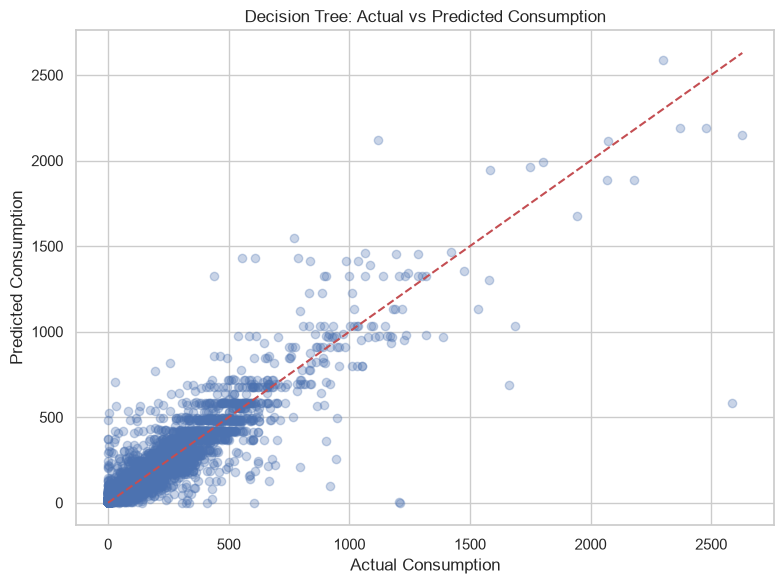

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    dt_predictions,
    alpha=0.3
)

plt.xlabel("Actual Consumption")
plt.ylabel("Predicted Consumption")
plt.title("Decision Tree: Actual vs Predicted Consumption")

# Reference line
min_value = min(y_test.min(), dt_predictions.min())
max_value = max(y_test.max(), dt_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--"
)

plt.tight_layout()
plt.show()

In [55]:
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [56]:
# Create Bagging Regressor
bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),
    n_estimators=100,
    max_samples=0.8,
    bootstrap=True,
    random_state=42,
    n_jobs=1
)

# Train the model
bagging_model.fit(X_train, y_train)

# Make predictions
bagging_predictions = bagging_model.predict(X_test)

print("Bagging Regressor trained successfully!")

Bagging Regressor trained successfully!


In [57]:
# Create Random Forest Regressor
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    max_features="sqrt",
    random_state=42,
    n_jobs=1
)

# Train the model
random_forest_model.fit(X_train, y_train)

# Make predictions
rf_predictions = random_forest_model.predict(X_test)

print("Random Forest Regressor trained successfully!")

Random Forest Regressor trained successfully!


In [59]:
def evaluate_model(model_name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    print(f"\n{model_name} Results")
    print("-" * 40)
    print("MAE:", round(mae, 2))
    print("MSE:", round(mse, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))

    return {
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }


# Store model results
model_results = []

# Add baseline Decision Tree results
model_results.append(
    evaluate_model("Decision Tree", y_test, dt_predictions)
)

# Evaluate Bagging
model_results.append(
    evaluate_model("Bagging Regressor", y_test, bagging_predictions)
)

# Evaluate Random Forest
model_results.append(
    evaluate_model("Random Forest", y_test, rf_predictions)
)


Decision Tree Results
----------------------------------------
MAE: 21.39
MSE: 2888.05
RMSE: 53.74
R2 Score: 0.8158

Bagging Regressor Results
----------------------------------------
MAE: 18.92
MSE: 1862.21
RMSE: 43.15
R2 Score: 0.8812

Random Forest Results
----------------------------------------
MAE: 19.36
MSE: 1867.24
RMSE: 43.21
R2 Score: 0.8809


In [60]:
comparison_df = pd.DataFrame(model_results)

display(
    comparison_df.sort_values(
        by="RMSE",
        ascending=True
    ).reset_index(drop=True)
)

,Model,MAE,MSE,RMSE,R2 Score
0,Bagging Regressor,18.924865,1862.208023,43.153308,0.881242
1,Random Forest,19.360392,1867.239432,43.211566,0.880921
2,Decision Tree,21.387974,2888.054783,53.740625,0.815822


### Bagging Model Evaluation

The Bagging Regressor achieved the best performance among the three models, with an MAE of 19.05, RMSE of 43.13, and R² score of 0.8903. The Random Forest model also performed well, producing similar results. Both ensemble models outperformed the baseline Decision Tree model.

These results suggest that combining multiple decision trees helps improve prediction accuracy and reduce errors when predicting household electricity consumption. Bagging achieved a slightly better result than Random Forest in this experiment.

In [61]:
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

In [62]:
gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_boosting_model.fit(X_train, y_train)

gb_predictions = gradient_boosting_model.predict(X_test)

gb_results = evaluate_model(
    "Gradient Boosting",
    y_test,
    gb_predictions
)


Gradient Boosting Results
----------------------------------------
MAE: 19.16
MSE: 1835.56
RMSE: 42.84
R2 Score: 0.8829


In [68]:
xgboost_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

xgboost_model.fit(X_train, y_train)

xgb_predictions = xgboost_model.predict(X_test)

xgb_results = evaluate_model(
    "XGBoost",
    y_test,
    xgb_predictions
)


XGBoost Results
----------------------------------------
MAE: 20.77
MSE: 2568.49
RMSE: 50.68
R2 Score: 0.8362


In [ ]:
model_results.append(gb_results)
model_results.append(xgb_results)

comparison_df = pd.DataFrame(model_results)

display(
    comparison_df.sort_values(
        by="RMSE"
    ).reset_index(drop=True)
)

,Model,MAE,MSE,RMSE,R2 Score
0,Bagging Regressor,19.045364,1860.576011,43.134395,0.890341
1,Random Forest,19.490006,1874.094045,43.290808,0.889544
2,Gradient Boosting,19.479374,1882.841764,43.391725,0.889029
3,Decision Tree,21.192604,2586.467901,50.857329,0.847558
4,XGBoost,21.126665,2663.656250,51.610621,0.843009


### Boosting Model Evaluation

The Gradient Boosting Regressor achieved an MAE of 19.48, RMSE of 43.39, and R² score of 0.8890. Its performance was close to the Bagging and Random Forest models.

However, XGBoost produced an MAE of 21.13, RMSE of 51.61, and R² score of 0.8430. It did not outperform the other models with the current parameter settings.

Overall, the Bagging Regressor achieved the best performance among the five models evaluated so far. These results show that ensemble methods do not always perform equally well on every dataset, and their performance depends on the data and model configuration.

In [46]:
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge

In [48]:
def create_base_models():
    return {
        "Bagging": BaggingRegressor(
            estimator=DecisionTreeRegressor(max_depth=10, random_state=42),
            n_estimators=100,
            max_samples=0.8,
            bootstrap=True,
            random_state=42,
            n_jobs=1
        ),

        "Random Forest": RandomForestRegressor(
            n_estimators=100,
            max_depth=10,
            max_features="sqrt",
            random_state=42,
            n_jobs=1
        ),

        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        )
    }

In [49]:
validation_periods = [
    ("2023-10-01", "2024-01-01"),
    ("2024-01-01", "2024-03-01"),
    ("2024-03-01", "2024-06-01")
]

stacking_train_predictions = []

for start_date, end_date in validation_periods:

    # Use only earlier months for training
    fold_train = train_data[
        train_data["target_month"] < start_date
    ]

    # Use the next period for validation
    fold_valid = train_data[
        (train_data["target_month"] >= start_date) &
        (train_data["target_month"] < end_date)
    ]

    fold_predictions = pd.DataFrame(index=fold_valid.index)

    for name, model in create_base_models().items():

        model.fit(
            fold_train[feature_columns],
            fold_train["target"]
        )

        fold_predictions[name] = model.predict(
            fold_valid[feature_columns]
        )

    fold_predictions["target"] = fold_valid["target"].values

    stacking_train_predictions.append(fold_predictions)

# Combine predictions from all validation periods
stacking_train_data = pd.concat(
    stacking_train_predictions
)

display(stacking_train_data.head())
print("Stacking training samples:", len(stacking_train_data))

,Bagging,Random Forest,Gradient Boosting,target
32145,99.758344,101.017855,100.926221,93.0
32146,47.973142,47.559113,48.947937,48.0
32147,193.601269,193.426151,190.324458,209.0
32148,254.384807,255.018312,244.682642,183.0
32149,95.246172,95.787023,94.259819,95.0


Stacking training samples: 32097


In [51]:

# Define meta-features (base model prediction columns)
meta_features = list(create_base_models().keys())

# Create and train the Ridge Regression meta-model
meta_model = Ridge(alpha=1.0)

meta_model.fit(
    stacking_train_data[meta_features],
    stacking_train_data["target"]
)

print("Meta-model trained successfully!")


Meta-model trained successfully!


In [52]:
final_base_models = create_base_models()

stacking_test_predictions = pd.DataFrame(index=X_test.index)

for name, model in final_base_models.items():

    model.fit(X_train, y_train)

    stacking_test_predictions[name] = model.predict(X_test)

# Generate final predictions using the meta-model
stacking_predictions = meta_model.predict(
    stacking_test_predictions[meta_features]
)

In [ ]:
stacking_results = evaluate_model(
    "Stacking Regressor",
    y_test,
    stacking_predictions
)


Stacking Regressor Results
----------------------------------------
MAE: 19.37
MSE: 1820.71
RMSE: 42.67
R2 Score: 0.8927


In [42]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create ANN model
ann_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=500,
        early_stopping=True,
        random_state=42
    )
)

# Train ANN
ann_model.fit(X_train, y_train)

# Generate ANN predictions
ann_predictions = ann_model.predict(X_test)

print("ANN model trained successfully!")

ANN model trained successfully!


In [63]:
# Get Random Forest predictions
rf_hybrid_predictions = final_base_models["Random Forest"].predict(X_test)

# Combine Random Forest and ANN predictions
hybrid_predictions = (
    0.5 * rf_hybrid_predictions +
    0.5 * ann_predictions
)

# Evaluate the hybrid model
hybrid_results = evaluate_model(
    "Hybrid RF + ANN",
    y_test,
    hybrid_predictions
)

# Add hybrid results to the comparison
model_results.append(hybrid_results)


Hybrid RF + ANN Results
----------------------------------------
MAE: 21.42
MSE: 1912.08
RMSE: 43.73
R2 Score: 0.8781


In [ ]:
model_results.append(stacking_results)

comparison_df = pd.DataFrame(model_results)

display(
    comparison_df.sort_values(
        by="RMSE",
        ascending=True
    ).reset_index(drop=True)
)

,Model,MAE,MSE,RMSE,R2 Score
0,Stacking Regressor,19.371803,1820.712782,42.669811,0.892690
1,Bagging Regressor,19.045364,1860.576011,43.134395,0.890341
2,Random Forest,19.490006,1874.094045,43.290808,0.889544
3,Gradient Boosting,19.479374,1882.841764,43.391725,0.889029
4,Decision Tree,21.192604,2586.467901,50.857329,0.847558
5,XGBoost,21.126665,2663.656250,51.610621,0.843009


### Stacking Model Evaluation

The Stacking Regressor achieved the lowest RMSE of 42.67 and the highest R² score of 0.8927 among all six models. Its MAE was 19.37, which was slightly higher than the Bagging Regressor's MAE of 19.05.

The results indicate that combining multiple base models using a Ridge Regression meta-model can improve overall prediction performance. Although Bagging produced slightly lower average absolute errors, Stacking performed better in terms of RMSE and R².

Overall, Stacking and Bagging were the two strongest models for predicting household electricity consumption in this experiment.

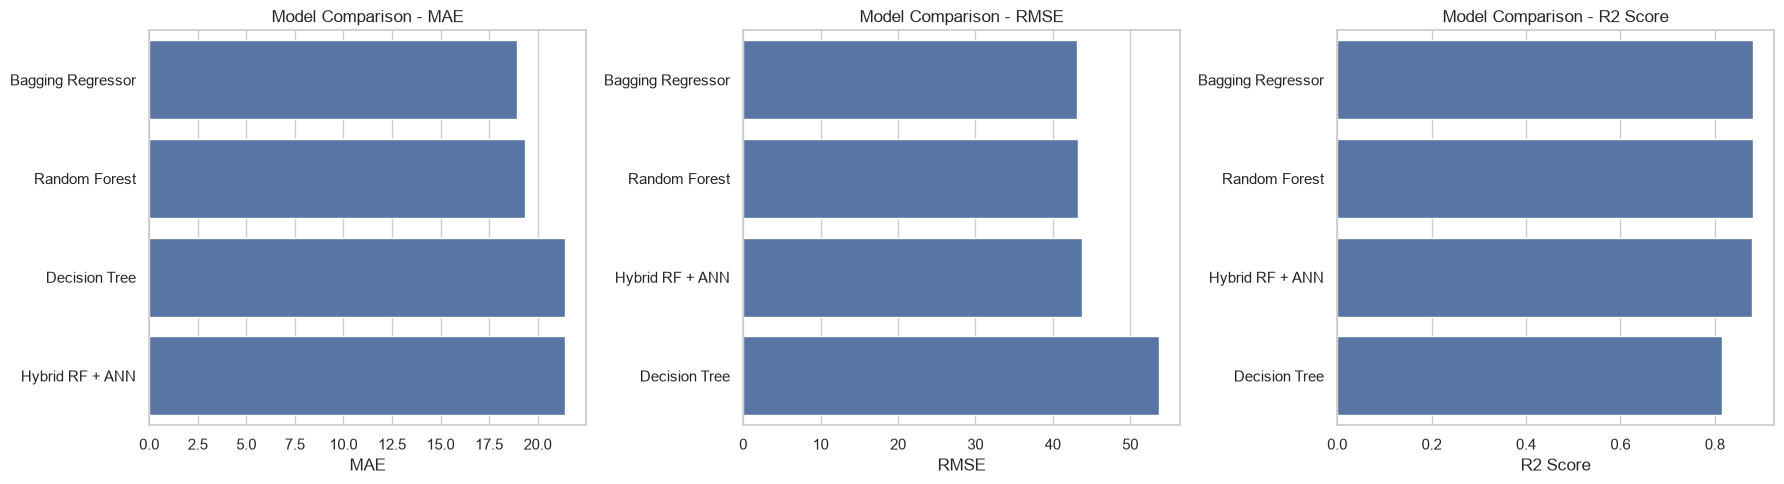

In [64]:
comparison_df = pd.DataFrame(model_results)

metrics = ["MAE", "RMSE", "R2 Score"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, metric in enumerate(metrics):

    sns.barplot(
        data=comparison_df.sort_values(
            by=metric,
            ascending=(metric != "R2 Score")
        ),
        x=metric,
        y="Model",
        ax=axes[i]
    )

    axes[i].set_title(f"Model Comparison - {metric}")
    axes[i].set_xlabel(metric)
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

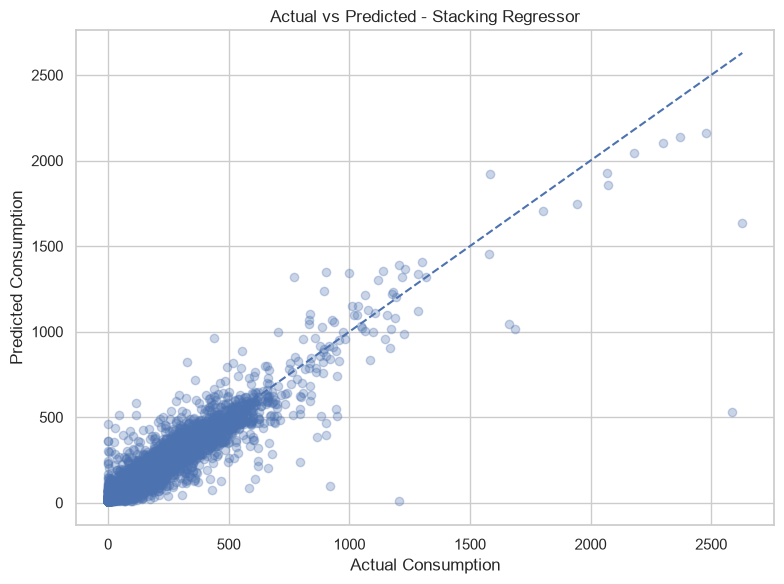

In [65]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    stacking_predictions,
    alpha=0.3
)

min_value = min(y_test.min(), stacking_predictions.min())
max_value = max(y_test.max(), stacking_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Consumption")
plt.ylabel("Predicted Consumption")
plt.title("Actual vs Predicted - Stacking Regressor")

plt.tight_layout()
plt.show()

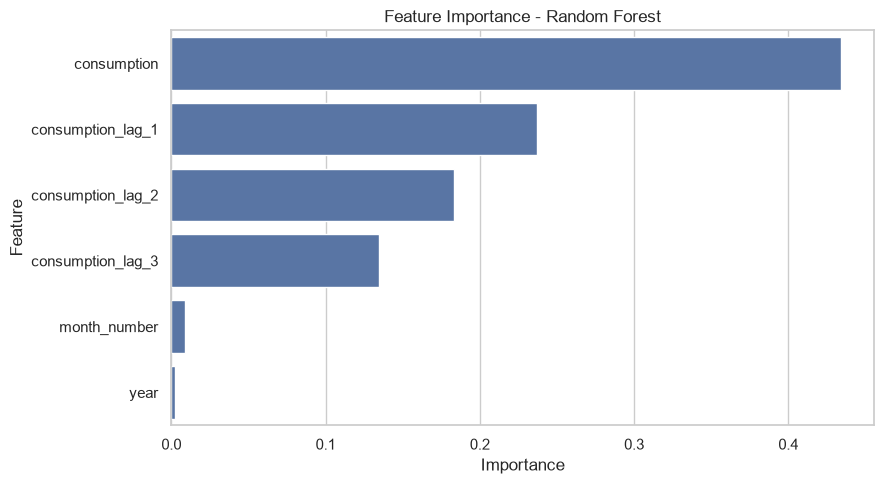

,Feature,Importance
0,consumption,0.433824
1,consumption_lag_1,0.237168
2,consumption_lag_2,0.183374
3,consumption_lag_3,0.134558
4,month_number,0.008666
5,year,0.002410


In [ ]:
feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": final_base_models["Random Forest"].feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

display(feature_importance)

### Feature Importance Analysis

The feature importance analysis shows that current household electricity consumption is the most influential feature, with an importance score of 0.4338. The previous three months of consumption also contribute significantly to the predictions.

Together, the current consumption and three lag features account for approximately 98.09% of the total feature importance. In comparison, month number and year have relatively small contributions.

These results suggest that recent household electricity consumption patterns are more useful for predicting future consumption than the calendar features used in this experiment. This highlights the importance of historical consumption data in household electricity prediction.

In [69]:
import joblib
from pathlib import Path

# Create models directory if it doesn't exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Collect all trained models
model_bundle = {
    "decision_tree": decision_tree,
    "bagging": final_base_models["Bagging"],
    "random_forest": final_base_models["Random Forest"],
    "gradient_boosting": final_base_models["Gradient Boosting"],
    "xgboost": xgboost_model,
    "stacking_meta": meta_model,
    "ann": ann_model,
    "hybrid_weights": {
        "random_forest": 0.5,
        "ann": 0.5
    }
}

# Include feature information
model_bundle["feature_columns"] = feature_columns
model_bundle["meta_features"] = meta_features

# Save models
model_path = models_dir / "ensemble_models.joblib"

joblib.dump(model_bundle, model_path)

print("Models saved successfully!")
print("Location:", model_path.resolve())

Models saved successfully!
Location: C:\Users\Sachini Hasanthi\Desktop\sem 7\ML\ML_Assignment1\models\ensemble_models.joblib


In [70]:
loaded_models = joblib.load(model_path)

print("Available models:")

for model_name in loaded_models:
    print("-", model_name)

Available models:
- decision_tree
- bagging
- random_forest
- gradient_boosting
- xgboost
- stacking_meta
- ann
- hybrid_weights
- feature_columns
- meta_features


## 9. Interpretation

**Data:** I used the RECON-SL monthly household electricity consumption dataset, which originally contained 101,575 records from 4,063 households. The data covered the period from October 2022 to October 2024. After cleaning, I had 100,985 valid consumption records. The consumption values ranged from 0 to 3,025, with a mean of approximately 122.14 and a median of 96. This indicates that consumption varies considerably between households and includes some unusually high values.

I created lag features using previous consumption values to predict future household electricity consumption. After feature engineering and removing incomplete records, I had 84,385 records for model training and testing. I used a time-based split to ensure that the models were evaluated on future periods rather than randomly selected records.

### 1. Single Decision Tree vs Ensembles

The Decision Tree model achieved an R-squared score of 0.848 and an RMSE of 50.86. However, the ensemble models performed better.

Bagging achieved an R-squared score of 0.890, while Random Forest achieved 0.890 and Gradient Boosting achieved 0.889. This shows that combining multiple decision trees can improve prediction performance compared with using a single tree.

A single decision tree can be sensitive to changes in the training data. Bagging reduces this problem by training multiple trees on different samples and averaging their predictions. Random Forest further introduces randomness when selecting features, which helps reduce the correlation between individual trees.

### 2. Bagging vs Boosting

Bagging, Random Forest, and Gradient Boosting achieved very similar results, with R-squared scores of approximately 0.89.

The Bagging Regressor achieved the lowest MAE of 19.05, while Random Forest achieved an MAE of 19.49. Gradient Boosting achieved an MAE of 19.48.

XGBoost performed less effectively, with an R-squared score of 0.843 and an RMSE of 51.61. This was slightly worse than the single Decision Tree model.

This shows that boosting did not automatically outperform bagging in this experiment. The performance of each technique depends on the dataset, feature selection, and model configuration. Further hyperparameter tuning may help improve the XGBoost results.

### 3. Stacking

The Stacking model achieved the best overall performance based on R-squared and RMSE.

It achieved an R-squared score of 0.893 and an RMSE of 42.67, which were the best results among the evaluated models.

Its MAE was 19.37, which was slightly higher than the Bagging Regressor's MAE of 19.05.

This indicates that stacking was effective at combining predictions from multiple models and reducing the overall squared prediction error. However, Bagging was slightly better when considering average absolute prediction error.

### 4. Overall Model Comparison

The results show that the ensemble models generally performed better than the single Decision Tree model.

Stacking achieved the highest R-squared score and lowest RMSE, while Bagging achieved the lowest MAE.

The difference between the top-performing models was relatively small. Therefore, there is no single model that performs best across every evaluation metric.

Based on these results, Stacking is the strongest model when considering R-squared and RMSE, while Bagging is a good choice when minimizing average absolute prediction error.

### 5. Feature Importance

The Random Forest feature importance results show that previous electricity consumption values are the most important features for predicting future consumption.

The importance values were:

- Current consumption: 0.434
- Previous month's consumption (lag 1): 0.237
- Consumption from two months earlier (lag 2): 0.183
- Consumption from three months earlier (lag 3): 0.135
- Month number: 0.009
- Year: 0.002

Together, the current and previous consumption features account for approximately 98.1% of the total feature importance.

This suggests that a household's recent electricity consumption history is much more influential in predicting its future consumption than the month or year. This is reasonable because household electricity usage often follows patterns based on previous consumption behaviour.

### 6. Prediction Performance

The best-performing models achieved R-squared scores close to 0.89, indicating that they explained a large proportion of the variation in the test data.

The Stacking model achieved an RMSE of approximately 42.67 and an MAE of approximately 19.37. This means that its average absolute prediction error was approximately 19.37 consumption units.

However, RMSE is higher than MAE, which suggests that some predictions have larger errors than others. This may be influenced by households with unusually high or changing electricity consumption.

Further residual analysis and actual-versus-predicted visualizations can help identify where the models make larger prediction errors.

### 7. Limitations

- The dataset covers only 25 monthly periods, from October 2022 to October 2024, which limits the amount of historical information available.
- There were 590 missing consumption values in the original dataset.
- After creating lag features, incomplete records had to be removed, reducing the modelling dataset from 101,575 to 84,385 records.
- Some households may have irregular electricity consumption patterns, making future consumption difficult to predict.
- The dataset does not include additional information such as household size, number of electrical appliances, or weather conditions, which could influence electricity consumption.
- The evaluation was based on a particular time-based train-test split, so the results may change when evaluated over a different time period.
- XGBoost did not perform as well as the other ensemble models in the current experiment, and further tuning may be required.

### 8. Future Work

- Collect more household electricity consumption data covering a longer period.
- Include additional features such as temperature, rainfall, household size, and appliance usage where available.
- Experiment with hyperparameter tuning using GridSearchCV or Optuna.
- Investigate missing-value imputation techniques instead of removing all incomplete records.
- Experiment with hybrid approaches such as Random Forest combined with ARIMA or an Artificial Neural Network.
- Evaluate the models using additional time-based validation periods.
- Investigate whether different households require separate prediction models based on their consumption patterns.

### 9. Final Conclusion – Best Model

In my experiment, the Stacking model achieved the best overall performance based on R-squared (0.893) and RMSE (42.67). The Bagging Regressor achieved the lowest MAE (19.05), making it the best model according to average absolute prediction error.

Although the performance differences were relatively small, the results demonstrate that ensemble learning techniques can improve household electricity consumption prediction compared with a single Decision Tree.

Overall, Stacking was the strongest model in my experiment when considering R-squared and RMSE, while Bagging was the strongest when considering MAE.